# Notebook 7: Analytical Results

The earlier notebooks establish their findings by simulation. For a theory paper
the strongest of those findings are better stated as theorems, with the
simulations as confirmation rather than as the whole evidence. This notebook does
that for five results. Each is stated and proved in plain terms, then checked in
code: a symbolic check where that helps, and a numerical check that the simulated
quantity matches the closed form.

- **T1** A weighted sum returns exactly one verdict, so it cannot contradict
  itself the way a consensus rule can. (Berman's second claim, made structural.)
- **T2** Conferred weight does not depend on how often a principle is invoked, so
  weight and uptake can come apart. (Notebook 2's dissociation, made exact.)
- **T3** A weighted sum responds to activation magnitudes; a lexical rule does
  not. (The nonlexicality requirement R3, made exact.)
- **T4** Determinacy is a closed-form function of the threshold, and the weights
  enter only through a single scale. (Why the threshold dominates.)
- **T5** Even with equal weights, a weighted sum is not the same as counting
  votes. (Refutes the claim that equal weights collapse the model to counting.)

## Setup

On Colab this mounts your Google Drive and works inside the project folder, so the
shared core, the data, and the figures live in one place and persist after the
runtime resets. Run locally, it just uses the current folder. The next cell then
writes the shared core; everything after imports from it.

In [1]:
import os
# The project folder on Google Drive (edit if you move the project):
PROJECT = '/content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Berman Modeling/Experiment/Run_2026-06'
try:
    from google.colab import drive            # on Colab: mount Drive and work in the project folder
    drive.mount('/content/drive')
    os.makedirs(PROJECT, exist_ok=True); os.chdir(PROJECT)
    print('Colab: mounted Drive, working in', os.getcwd())
except ImportError:
    print('Local: working in', os.getcwd())   # already in the project folder

Mounted at /content/drive
Colab: mounted Drive, working in /content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Berman Modeling/Experiment/Run_2026-06


In [2]:
%%writefile berman_core.py
"""
berman_core.py — shared, corrected core for the Berman Modeling rebuild (2026-06).

ONE source of truth for the SAW model, principle sets, Hart baselines, a *seeded*
bootstrap, the activation generators, the weight-tolerance (critical-sigma)
machinery, and the redesigned evaluation criteria. Every notebook %%writefile's
this file and `from berman_core import *`, so a fix here propagates everywhere
(ends the verbatim-copy drift of the old notebooks).

Design decisions baked in (vs. the old code):
  * Determinacy convention is strict |F| > tau, matching the manuscript.
  * RNG is always explicit (np.random.default_rng(seed)); bootstrap is seeded
    and vectorized, so every CI is reproducible.
  * One determinacy cutoff (DEFAULT_TAU) everywhere — no 0.05-here-0.2-there.
  * Corrected category map: federalism is STRUCTURAL, not moral.
  * Criteria are split into REQUIREMENTS (R1-R4, pass/fail, derived from what
    Berman actually claims) and DESCRIPTIVE measures (D1-D2, reported, never used
    to fail the theory). See CONCEPTUAL_AUDIT_vs_Berman.md.
"""
from __future__ import annotations

from dataclasses import dataclass
from typing import Dict, List, Optional, Callable, Tuple

import numpy as np

__all__ = [
    "DEFAULT_TAU", "Principle", "NAMED_PRINCIPLES", "CATEGORY_INDEX",
    "make_weights", "named_weight_vector", "category_of",
    "net_force", "is_determinate", "determinacy_rate",
    "random_activations", "category_correlated_activations", "fully_correlated_activations",
    "bootstrap_ci", "critical_sigma", "CRITICAL_SIGMA_CEIL",
    "hart_hierarchical_determinate", "hart_consensus_determinate", "hart_advantage",
    "hart_validation_status",
    "nonlexicality_score", "ordinalize", "saw_verdict", "lexicographic_verdict",
    "weight_cv", "n_survivors", "cluster_gap",
    "METHODOLOGIES", "methodology_tendencies", "LegalSystem",
    "gmm_bimodal", "bimodality_coefficient",
    "RelianceSystem", "weight_entropy", "gini", "n_bins_occupied",
]

# ---------------------------------------------------------------------------
# Determinacy convention
# ---------------------------------------------------------------------------
DEFAULT_TAU: float = 0.20  # a case is determinate when |F| > tau (strict)


# ---------------------------------------------------------------------------
# Principles and categories  (federalism corrected to 'structural')
# ---------------------------------------------------------------------------
@dataclass
class Principle:
    name: str
    weight: float
    category: str = "structural"  # one of: 'textual', 'structural', 'moral'

    def __post_init__(self) -> None:
        assert 0.0 <= self.weight <= 1.0, f"weight out of [0,1]: {self.weight}"
        assert self.category in ("textual", "structural", "moral"), self.category


# The baseline 9-principle set. Order is fixed; categories are the corrected map.
NAMED_PRINCIPLES: List[Tuple[str, str]] = [
    ("text",       "textual"),
    ("original",   "textual"),
    ("precedent",  "structural"),
    ("structure",  "structural"),
    ("federalism", "structural"),   # <-- was grouped with 'moral' in the old code (bug)
    ("dignity",    "moral"),
    ("equality",   "moral"),
    ("liberty",    "moral"),
    ("welfare",    "moral"),
]

CATEGORY_INDEX: Dict[str, List[int]] = {
    cat: [i for i, (_, c) in enumerate(NAMED_PRINCIPLES) if c == cat]
    for cat in ("textual", "structural", "moral")
}


def category_of(i: int) -> str:
    return NAMED_PRINCIPLES[i][1]


# ---------------------------------------------------------------------------
# Weight generators
# ---------------------------------------------------------------------------
def make_weights(n: int, distribution: str, seed: int) -> np.ndarray:
    """Generate n weights. 'uniform' ~U(.60,.70); 'moderate' ~U(.50,.80);
    'high' ~U(.30,.95). Berman's weights are 'rough' (slight..nearly conclusive)."""
    rng = np.random.default_rng(seed)
    if distribution == "uniform":
        return rng.uniform(0.60, 0.70, n)
    if distribution == "moderate":
        return rng.uniform(0.50, 0.80, n)
    if distribution == "high":
        return rng.uniform(0.30, 0.95, n)
    raise ValueError(f"unknown distribution: {distribution}")


def named_weight_vector(distribution: str = "moderate", seed: int = 0) -> np.ndarray:
    """Weights for the 9 NAMED_PRINCIPLES under a given distribution."""
    return make_weights(len(NAMED_PRINCIPLES), distribution, seed)


# ---------------------------------------------------------------------------
# SAW model (nonlexical aggregation)
# ---------------------------------------------------------------------------
def net_force(weights: np.ndarray, activations: np.ndarray) -> np.ndarray:
    """F = sum_i w_i * a_i. Vectorized over a (..., n) activation array."""
    weights = np.asarray(weights, float)
    activations = np.asarray(activations, float)
    return np.sum(weights * activations, axis=-1)


def is_determinate(weights, activations, tau: float = DEFAULT_TAU):
    return np.abs(net_force(weights, activations)) > tau


def determinacy_rate(weights, activation_matrix, tau: float = DEFAULT_TAU) -> float:
    return float(np.mean(is_determinate(weights, activation_matrix, tau)))


# ---------------------------------------------------------------------------
# Activation generators (the conservative independent baseline + realistic structure)
# ---------------------------------------------------------------------------
def random_activations(n_cases: int, n_principles: int, rng: np.random.Generator) -> np.ndarray:
    """Independent activations ~ U(-1, 1). The conservative baseline."""
    return rng.uniform(-1.0, 1.0, size=(n_cases, n_principles))


def category_correlated_activations(n_cases: int, rng: np.random.Generator,
                                    rho: float = 0.7) -> np.ndarray:
    """Activations for the 9 NAMED_PRINCIPLES where principles in the same
    category share a common latent factor (textual together, structural together,
    moral together)."""
    n_p = len(NAMED_PRINCIPLES)
    a = np.empty((n_cases, n_p))
    for cat, idx in CATEGORY_INDEX.items():
        factor = rng.uniform(-1.0, 1.0, size=(n_cases, 1))
        idio = rng.uniform(-1.0, 1.0, size=(n_cases, len(idx)))
        a[:, idx] = np.clip(rho * factor + (1 - rho) * idio, -1.0, 1.0)
    return a


def fully_correlated_activations(n_cases: int, n_principles: int,
                                 rng: np.random.Generator, rho: float = 0.7) -> np.ndarray:
    """All principles share one latent factor."""
    factor = rng.uniform(-1.0, 1.0, size=(n_cases, 1))
    idio = rng.uniform(-1.0, 1.0, size=(n_cases, n_principles))
    return np.clip(rho * factor + (1 - rho) * idio, -1.0, 1.0)


# ---------------------------------------------------------------------------
# Bootstrap — SEEDED and vectorized (every CI is reproducible)
# ---------------------------------------------------------------------------
def bootstrap_ci(values, n_boot: int = 2000, ci: int = 95, seed: int = 0):
    """Return (mean, lo, hi) for a percentile bootstrap CI on the mean."""
    rng = np.random.default_rng(seed)
    arr = np.asarray(values, dtype=float)
    if arr.size == 0:
        return (float("nan"),) * 3
    means = rng.choice(arr, size=(n_boot, arr.size), replace=True).mean(axis=1)
    lo = float(np.percentile(means, (100 - ci) / 2))
    hi = float(np.percentile(means, 100 - (100 - ci) / 2))
    return float(arr.mean()), lo, hi


# ---------------------------------------------------------------------------
# Weight-uncertainty tolerance: critical sigma  (R2 — "rough weights suffice")
# ---------------------------------------------------------------------------
CRITICAL_SIGMA_CEIL = 1.0  # grid maximum; a returned value == this is right-censored


def critical_sigma(weights: np.ndarray, activation_matrix: np.ndarray,
                   tau: float = DEFAULT_TAU, accuracy: float = 0.80,
                   robust_thresh: float = 0.90, n_mc: int = 64, seed: int = 0,
                   sigma_grid: Optional[np.ndarray] = None) -> float:
    """Smallest weight-noise sigma at which fewer than `accuracy` of cases remain
    individually robust.

    Two-level definition: add N(0, sigma^2) to each weight (clipped to [0,1]); a
    *case* is robust at sigma if it keeps its unperturbed signed VERDICT
    (determinate-for / determinate-against / indeterminate) on at least
    `robust_thresh` of MC draws; sigma* is the smallest sigma at which the
    fraction of robust cases falls below `accuracy`.

    Verdict-stability (not just determinate/indeterminate class) so that a noise
    level that flips a determinate-for case to determinate-against counts as
    instability. The grid runs to CRITICAL_SIGMA_CEIL; a returned value equal to
    the ceiling is right-censored (true tolerance is >= ceiling) -- callers
    should flag these rather than average them as if measured.
    """
    rng = np.random.default_rng(seed)
    w = np.asarray(weights, float)
    A = np.asarray(activation_matrix, float)
    n_p = w.size
    if sigma_grid is None:
        sigma_grid = np.linspace(0.0, CRITICAL_SIGMA_CEIL, 51)

    true_F = A @ w
    true_v = np.sign(true_F); true_v[np.abs(true_F) <= tau] = 0    # (cases,) verdict
    noise = rng.standard_normal((n_mc, A.shape[0], n_p))          # (mc, cases, p)

    prev_sigma, prev_surv = 0.0, 1.0
    for sigma in sigma_grid:
        if sigma == 0:
            prev_sigma, prev_surv = 0.0, 1.0
            continue
        w_noisy = np.clip(w[None, None, :] + sigma * noise, 0.0, 1.0)
        F = np.einsum("mcp,cp->mc", w_noisy, A)                   # (mc, cases)
        v = np.sign(F); v[np.abs(F) <= tau] = 0
        agree_frac = np.mean(v == true_v[None, :], axis=0)        # per case
        survival = float(np.mean(agree_frac >= robust_thresh))
        if survival < accuracy:
            frac = (accuracy - prev_surv) / (survival - prev_surv)
            return float(prev_sigma + frac * (sigma - prev_sigma))
        prev_sigma, prev_surv = sigma, survival
    return float(sigma_grid[-1])  # right-censored at the ceiling


# ---------------------------------------------------------------------------
# Hart baselines  (R4 — "more law than Hart", reported as a margin/curve)
# ---------------------------------------------------------------------------
def hart_consensus_determinate(activations, frac: float = 0.6,
                               act_cut: float = 0.1) -> np.ndarray:
    """Consensus Hart (the faithful operationalization of Hart-as-validation):
    a case is determinate only when the share of *active* principles pointing the
    same direction exceeds `frac`. Hart requires agreement; below `frac` the law
    'runs out'."""
    A = np.atleast_2d(np.asarray(activations, float))
    pos = np.sum(A > act_cut, axis=1)
    neg = np.sum(A < -act_cut, axis=1)
    active = pos + neg
    with np.errstate(invalid="ignore", divide="ignore"):
        share = np.maximum(pos, neg) / np.where(active == 0, 1, active)
    return (active > 0) & (share > frac)


def hart_hierarchical_determinate(weights, activations, tier_of: np.ndarray,
                                  frac: float = 0.6, act_cut: float = 0.1,
                                  tau: float = DEFAULT_TAU) -> np.ndarray:
    """Charitable *lexical-priority* Hart: principles sit in priority tiers
    (0 = top). For each case, the highest-priority tier that has ANY active
    principle is DISPOSITIVE: that tier decides iff its active principles reach
    consensus (>= `frac` agree in sign); otherwise the law runs out. Lower tiers
    are NOT consulted once a higher tier is reached — that is the lexical priority
    Berman's nonlexical model is contrasted against, and it is what stops Hart
    from finding law in nearly every case via tier escape-hatches.
    """
    A = np.atleast_2d(np.asarray(activations, float))
    tier_of = np.asarray(tier_of, int)
    out = np.zeros(A.shape[0], dtype=bool)
    reached = np.zeros(A.shape[0], dtype=bool)  # a dispositive tier has been reached
    for t in np.unique(tier_of):
        idx = np.where(tier_of == t)[0]
        sub = A[:, idx]
        pos = np.sum(sub > act_cut, axis=1)
        neg = np.sum(sub < -act_cut, axis=1)
        active = pos + neg
        this_tier = (active > 0) & (~reached)        # cases first resolved at this tier
        with np.errstate(invalid="ignore", divide="ignore"):
            share = np.maximum(pos, neg) / np.where(active == 0, 1, active)
        out |= this_tier & (share > frac)             # decided iff consensus here (strict, matches consensus Hart)
        reached |= this_tier                           # dispositive; no escape downward
    return out


def hart_validation_status(activations, k: int = 2, act_cut: float = 0.5) -> np.ndarray:
    """Naive validation foil used to make Berman's 'no contradiction' point.

    A direction counts as independently 'validated' when at least `k` principles
    are strongly activated (|a| > act_cut) in that direction. Returns one integer
    code per case:
        0 = gap          (neither direction validated -> the law runs out)
        1 = for          (only the positive direction validated)
        2 = against      (only the negative direction validated)
        3 = contradiction(both directions validated -> q and not-q are both law)

    The point: code 3 is possible for a validation model, but impossible for
    Berman's aggregation, because a single net force has a single sign. So the sum
    never returns code 3.
    """
    A = np.atleast_2d(np.asarray(activations, float))
    pos = np.sum(A > act_cut, axis=1) >= k
    neg = np.sum(A < -act_cut, axis=1) >= k
    code = np.zeros(A.shape[0], dtype=int)
    code[pos & ~neg] = 1
    code[neg & ~pos] = 2
    code[pos & neg] = 3
    return code


def hart_advantage(weights, activation_matrix, tier_of, frac: float = 0.6,
                   tau: float = DEFAULT_TAU) -> float:
    """Berman determinacy rate minus hierarchical-Hart determinacy rate (a margin,
    not a pass/fail)."""
    berman = determinacy_rate(weights, activation_matrix, tau)
    hart = float(np.mean(hart_hierarchical_determinate(
        weights, activation_matrix, tier_of, frac=frac, tau=tau)))
    return berman - hart


# ---------------------------------------------------------------------------
# R3 — nonlexicality.  Does determination track activation MAGNITUDES (and many
# principles jointly), as Berman requires, rather than just signs/ranks (lexical)?
# ---------------------------------------------------------------------------
def ordinalize(weights: np.ndarray) -> np.ndarray:
    """Replace weights by rank-based pseudo-weights (1..n)/n — discards cardinal info."""
    order = np.argsort(np.argsort(weights))  # ranks 0..n-1
    return (order + 1) / len(weights)


# Verdict functions return an integer verdict per case: +1 / -1 (determinate for
# / against) or 0 (indeterminate). These are the inputs to the R3 nonlexicality
# probe and are reused by the aggregation-function suite.
def saw_verdict(weights, activation_matrix, tau: float = DEFAULT_TAU) -> np.ndarray:
    """Nonlexical: verdict from the *magnitude-weighted sum* of all principles."""
    F = np.asarray(activation_matrix, float) @ np.asarray(weights, float)
    v = np.sign(F)
    v[np.abs(F) <= tau] = 0
    return v.astype(int)


def lexicographic_verdict(weights, activation_matrix, act_cut: float = 0.05) -> np.ndarray:
    """Lexical: verdict from the SIGN of the single highest-weight active
    principle (Raz exclusionary-reasons style). This is the mode Berman's theory
    is defined against — included only as the lexical foil for the R3 probe."""
    w = np.asarray(weights, float)
    A = np.atleast_2d(np.asarray(activation_matrix, float))
    order = np.argsort(-w)  # highest weight first
    out = np.zeros(A.shape[0], dtype=int)
    decided = np.zeros(A.shape[0], dtype=bool)
    for j in order:
        active = (np.abs(A[:, j]) > act_cut) & (~decided)
        out[active] = np.sign(A[active, j]).astype(int)
        decided |= active
    return out


def nonlexicality_score(verdict_fn: Callable[[np.ndarray], np.ndarray],
                        activation_matrix: np.ndarray,
                        seed: int = 0, n_mc: int = 32, jitter: float = 0.20) -> float:
    """R3 probe. Fraction of cases whose VERDICT changes under a magnitude-only
    perturbation of activations that preserves every activation's sign AND the
    within-case rank order of |activation|.

    A lexical rule (decides on the top-ranked active principle) is invariant to
    such perturbations -> score ~ 0. A genuinely nonlexical, magnitude-aggregating
    rule (SAW) is sensitive -> score > 0. `verdict_fn(A)` maps an (n,9) activation
    matrix to an integer verdict array in {-1,0,+1}.
    """
    rng = np.random.default_rng(seed)
    A = np.asarray(activation_matrix, float)
    base = verdict_fn(A)
    rank = np.argsort(np.argsort(np.abs(A), axis=1), axis=1)  # rank of |a| within row
    n_p = A.shape[1]
    changed = np.zeros(A.shape[0])
    for _ in range(n_mc):
        mag = np.clip(np.abs(A) * (1 + rng.uniform(-jitter, jitter, A.shape)), 0, 1)
        sorted_mag = np.sort(mag, axis=1)
        # Strictly-increasing epsilon breaks ties created when two magnitudes both
        # clip to 1.0; without this, re-placing tied values by index can silently
        # change the rank order (and thus the decision of a lexical rule). This
        # guarantees |A2| keeps the ORIGINAL within-row rank order exactly.
        sorted_mag = sorted_mag + 1e-9 * np.arange(n_p)
        A2 = np.sign(A) * np.take_along_axis(sorted_mag, rank, axis=1)
        changed += (verdict_fn(A2) != base)
    return float(np.mean(changed / n_mc))


# ---------------------------------------------------------------------------
# Descriptive weight statistics (D1 gradation, and emergence diagnostics)
# ---------------------------------------------------------------------------
def weight_cv(weights: np.ndarray) -> float:
    w = np.asarray(weights, float)
    m = w.mean()
    return float(w.std() / m) if m > 0 else 0.0


def n_survivors(weights: np.ndarray, cutoff: float = 0.05) -> int:
    return int(np.sum(np.asarray(weights, float) > cutoff))


def cluster_gap(weights: np.ndarray) -> float:
    """Gap between the two k-means clusters of weights (bimodality diagnostic)."""
    w = np.sort(np.asarray(weights, float))
    if w.size < 2:
        return 0.0
    best = None
    for k in range(1, w.size):
        lo, hi = w[:k], w[k:]
        gap = hi.mean() - lo.mean()
        if best is None or gap > best:
            best = gap
    return float(best)


# ===========================================================================
# Agent-based model of weight emergence (Notebook 1)
# ===========================================================================
# A bench of judges, each carrying an interpretive methodology that sets how
# often it invokes each principle. A principle's emergent "uptake share" is how
# often the bench takes it up across decisions. This is a deliberately simple
# model of Berman's "taking-up" (JESP p. 302); it is NOT his full account of
# weight, which is conferred by reliance and by winning conflicts (pp. 322, 324)
# and is taken up in Notebook 1c. The emergent quantity here is called "uptake
# share," never "weight in Berman's sense."

METHODOLOGIES = ("textualist", "purposivist", "pragmatist", "originalist")

# For each methodology, the principles it tends to invoke often ('high') or
# rarely ('low'); anything unlisted is 'medium'. Names refer to NAMED_PRINCIPLES.
_METH_SETS = {
    "textualist":  {"high": {"text", "original"},
                    "low":  {"dignity", "equality", "liberty", "welfare"}},
    "purposivist": {"high": {"dignity", "equality", "liberty"},
                    "low":  {"text", "original", "federalism"}},
    "pragmatist":  {"high": {"welfare", "precedent"},
                    "low":  {"dignity", "equality", "original"}},
    "originalist": {"high": {"original", "text", "federalism"},
                    "low":  {"dignity", "equality", "liberty", "welfare"}},
}

# Invocation-probability ranges (high, medium, low) by how specialized the
# methodologies are. 'wide' = strong specialization (headline); 'narrow' = nearly
# homogeneous (used to show heterogeneity is necessary for the split).
_SPREAD_RANGES = {
    "wide":   ((0.85, 0.95), (0.35, 0.65), (0.02, 0.08)),
    "medium": ((0.70, 0.80), (0.40, 0.60), (0.15, 0.25)),
    "narrow": ((0.60, 0.70), (0.42, 0.58), (0.30, 0.40)),
}


def methodology_tendencies(methodology: str, spread: str, rng) -> np.ndarray:
    """A 9-vector of per-principle invocation probabilities for one judge of a
    given methodology, drawn from the high/medium/low ranges set by `spread`."""
    hi, med, lo = _SPREAD_RANGES[spread]
    sets = _METH_SETS[methodology]
    t = np.empty(len(NAMED_PRINCIPLES))
    for i, (name, _) in enumerate(NAMED_PRINCIPLES):
        rng_range = hi if name in sets["high"] else (lo if name in sets["low"] else med)
        t[i] = rng.uniform(*rng_range)
    return t


class LegalSystem:
    """A bench of judges whose case-by-case invocations produce emergent
    principle uptake-shares.

    `turnover` selects how judges are replaced over time:
      'static'      no replacement (the headline emergence must hold here);
      'fitness'     replace the least decisive 20% with mutated copies of the
                    most decisive 20% (the old, suspect, non-Bermanian rule);
      'appointment' replace a random 20%, reseated from the methodology pool;
      'noise'       replace a random 20% with mutated copies of random judges.
    The point of the four regimes is to show the emergent structure does NOT
    depend on the turnover rule.
    """

    def __init__(self, n_agents=100, methodology_mix=None, spread="wide",
                 use_threshold=True, threshold_pct=50, turnover="static",
                 boost_cut=0.3, learn_from_system=0.15, seed=0):
        # One master seed -> five independent streams. No global np.random.
        ss = np.random.SeedSequence(seed)
        (self._rng_agents, self._rng_panels, self._rng_cases,
         self._rng_dec, self._rng_rep) = (np.random.default_rng(s) for s in ss.spawn(5))
        self.n_agents = n_agents
        self.spread = spread
        self.use_threshold = use_threshold
        self.threshold_pct = threshold_pct
        self.turnover = turnover
        self.boost_cut = boost_cut
        self.learn_from_system = learn_from_system
        self.n_p = len(NAMED_PRINCIPLES)

        # Assign methodologies exactly (round-robin or a given mix), then permute
        # the arrangement with the seeded generator (never np.random.shuffle).
        if methodology_mix is None:
            base = [METHODOLOGIES[i % 4] for i in range(n_agents)]
        else:
            base = []
            for m, frac in methodology_mix.items():
                base += [m] * int(round(frac * n_agents))
            base = (base + [METHODOLOGIES[0]] * n_agents)[:n_agents]
        self.methodology = list(self._rng_agents.permutation(base))
        self.tendencies = np.array([methodology_tendencies(m, spread, self._rng_agents)
                                    for m in self.methodology])     # (n_agents, 9)
        self.system_weights = np.full(self.n_p, 0.5)                # uniform init
        self.raw_uptake = np.full(self.n_p, 0.5)                    # pre-threshold share
        self.success = np.zeros(n_agents)
        self.decisions = np.zeros(n_agents)
        self.trajectory = []

    def _recompute_weights(self, counts, total):
        raw = counts / max(total, 1)
        raw = raw / max(raw.max(), 1e-12)                           # normalize to max
        self.raw_uptake = raw.copy()                               # the pre-threshold vector
        w = raw.copy()
        if self.use_threshold:                                     # zero the bottom percentile
            cut = np.percentile(w, self.threshold_pct)
            w = np.where(w < cut, 0.0, w)
            if w.max() > 0:
                w = w / w.max()
        self.system_weights = w

    def _replace(self, idx_out, idx_template):
        for o, t in zip(idx_out, idx_template):
            self.methodology[o] = self.methodology[t]
            self.tendencies[o] = np.clip(self.tendencies[t] + self._rng_rep.normal(0, 0.03, self.n_p),
                                         0.02, 0.98)
            self.success[o] = 0.0
            self.decisions[o] = 0.0

    def _turnover_step(self):
        k = max(1, int(0.2 * self.n_agents))
        if self.turnover == "static":
            return
        if self.turnover == "fitness":
            # eligible only with >= 5 decisions, so 1-2-case luck cannot rank an agent
            rate = np.where(self.decisions >= 5, self.success / np.maximum(self.decisions, 1), -1.0)
            order = np.argsort(rate)
            self._replace(order[:k], order[-k:])                   # bottom k <- top k
        elif self.turnover == "appointment":
            for o in self._rng_rep.choice(self.n_agents, k, replace=False):
                m = METHODOLOGIES[int(self._rng_rep.integers(4))]
                self.methodology[o] = m
                self.tendencies[o] = methodology_tendencies(m, self.spread, self._rng_rep)
                self.success[o] = 0.0
                self.decisions[o] = 0.0
        elif self.turnover == "noise":
            self._replace(self._rng_rep.choice(self.n_agents, k, replace=False),
                          self._rng_rep.choice(self.n_agents, k, replace=False))

    def simulate(self, n_cases=2000, panel_size=9, update_every=100, selection_every=500):
        counts = np.zeros(self.n_p)
        total = 0
        A = self._rng_cases.uniform(-1, 1, size=(n_cases, self.n_p))           # case stream up front
        panels = np.array([self._rng_panels.choice(self.n_agents, panel_size, replace=False)
                           for _ in range(n_cases)])
        self.trajectory = []
        for c in range(n_cases):
            a = A[c]
            panel = panels[c]
            tend = self.tendencies[panel]                                      # (panel, 9)
            prob = 0.85 * tend + self.learn_from_system * self.system_weights[None, :]
            boost = np.abs(a) > self.boost_cut                                 # strong activations invoked more
            prob = np.where(boost[None, :], np.minimum(prob * 1.15, 0.99), prob)
            invoked = self._rng_dec.uniform(size=(panel_size, self.n_p)) < prob
            counts += invoked.sum(axis=0)
            total += int(invoked.sum())
            forces = (invoked * self.system_weights[None, :] * a[None, :]).sum(axis=1)  # SAW per judge
            med = np.median(np.abs(forces))
            self.success[panel] += (np.abs(forces) >= med)                     # fitness bookkeeping
            self.decisions[panel] += 1
            if (c + 1) % update_every == 0:
                self._recompute_weights(counts, total)
                # record the smooth pre-threshold uptake for convergence/trajectory
                self.trajectory.append((c + 1, self.raw_uptake.copy()))
            if (c + 1) % selection_every == 0:
                self._turnover_step()
        self._recompute_weights(counts, total)
        return self.system_weights


def gmm_bimodal(values, seed=0, dbic_thresh=10.0):
    """Two-vs-one Gaussian-mixture BIC test for bimodality. Returns
    (dbic, separated, is_bimodal): dbic = BIC(1) - BIC(2) (larger favors two
    components); `separated` requires the two means be at least one larger-
    component SD apart (rejects two overlapping Gaussians). Deterministic."""
    from sklearn.mixture import GaussianMixture
    x = np.asarray(values, float).reshape(-1, 1)
    if len(np.unique(np.round(x, 6))) < 2:
        return 0.0, False, False
    g1 = GaussianMixture(1, random_state=seed, n_init=5).fit(x)
    g2 = GaussianMixture(2, random_state=seed, n_init=5).fit(x)
    dbic = float(g1.bic(x) - g2.bic(x))
    means = g2.means_.ravel()
    sds = np.sqrt(g2.covariances_.ravel())
    separated = bool(abs(means[0] - means[1]) > sds.max())
    return dbic, separated, bool(dbic > dbic_thresh and separated)


def bimodality_coefficient(values):
    """Sarle's bimodality coefficient. > 0.555 suggests bimodality. Underpowered
    for very small n, so use it on pooled data, not a single 9-vector."""
    from scipy import stats as _st
    x = np.asarray(values, float)
    n = x.size
    if n < 4:
        return float("nan")
    g = _st.skew(x); k = _st.kurtosis(x, fisher=True)
    return float((g**2 + 1) / (k + 3 * (n - 1)**2 / ((n - 2) * (n - 3))))


# ===========================================================================
# Reliance / by-battle weight conferral (Notebook 2)
# ===========================================================================
# Berman's conferred weight (JESP pp. 322, 324): a principle gains weight by
# winning CONTESTED, DISPOSITIVE battles, amplified by how much the deciding
# precedent is later RELIED UPON (cited), decayed gradually, and removed when a
# precedent is OVERRULED. Battles are decided by a FIXED exogenous "pressure"
# structure (the practice), NOT by the conferred weight being built: making it
# literally circular ("weight made so by battle") produces runaway lock-in, so
# the decision and the read-out are decoupled. There is NO weight floor -- that
# is what made the old "precedent stock" collapse to uniform weights.

def weight_entropy(w):
    """Shannon entropy of a normalized weight vector (higher = more spread)."""
    w = np.asarray(w, float); s = w.sum()
    if s <= 0:
        return 0.0
    p = w / s; p = p[p > 0]
    return float(-(p * np.log(p)).sum())


def gini(w):
    """Gini coefficient of a weight vector (0 = equal, ->1 = concentrated)."""
    w = np.sort(np.asarray(w, float)); n = len(w)
    if w.sum() == 0:
        return 0.0
    return float((2 * np.arange(1, n + 1) - n - 1).dot(w) / (n * w.sum()))


def n_bins_occupied(w, edges=(0.2, 0.4, 0.6, 0.8)):
    """How many of Berman's ~5 rough weight bands a weight vector occupies."""
    return int(len(np.unique(np.digitize(np.asarray(w, float), edges))))


class RelianceSystem:
    """Conferred weight as reliance-amplified, decayed, overruling-prunable
    battle-victories. Battles are decided by `pressure_weights` (fixed), and the
    conferred weight is read out separately, so the dynamics cannot lock in."""

    def __init__(self, pressure_weights=None, invoke_prob=None, salience=None,
                 activations="correlated", cite_mode="similarity", n_cite=3,
                 overrule_rate=0.02, decay_rate=0.9995, clash_cut=0.10,
                 feedback_alpha=0.0, tau=DEFAULT_TAU, seed=0):
        # feedback_alpha > 0 feeds the running conferred weight back into the
        # battle decision (the literally-circular "made so by battle"). It exists
        # only to DEMONSTRATE the runaway lock-in that justifies the decoupled
        # design; the headline runs use feedback_alpha = 0.
        ss = np.random.SeedSequence(seed)
        (self._rng_cases, self._rng_cite, self._rng_over,
         self._rng_inv, self._rng_setup) = (np.random.default_rng(s) for s in ss.spawn(5))
        n_p = len(NAMED_PRINCIPLES)
        self.n_p = n_p
        self.pressure_weights = (named_weight_vector("high", seed) if pressure_weights is None
                                 else np.asarray(pressure_weights, float))
        # uptake invocation propensity. It tracks the same exogenous PRESSURE
        # structure that decides battles (a principle pressed harder is invoked
        # more and can win more), so uptake and conferred weight are correlated
        # but distinct. It is NOT a function of the conferred weight being built,
        # so the two can still come apart (the forced-loser demo overrides it).
        self.invoke_prob = (np.clip(0.2 + 0.7 * (self.pressure_weights / self.pressure_weights.max())
                                    + self._rng_setup.normal(0, 0.05, n_p), 0.05, 0.98)
                            if invoke_prob is None else np.asarray(invoke_prob, float))
        self.salience = np.ones(n_p) if salience is None else np.asarray(salience, float)
        self.activations, self.cite_mode, self.n_cite = activations, cite_mode, n_cite
        self.overrule_rate, self.decay_rate, self.clash_cut, self.tau = \
            overrule_rate, decay_rate, clash_cut, tau
        self.feedback_alpha = feedback_alpha
        self.invoked_total = np.zeros(n_p)
        self.n_seen = 0
        self._ns = 0

    def run(self, n_cases=2000):
        np_ = self.n_p
        A = (category_correlated_activations(n_cases, self._rng_cases) if self.activations == "correlated"
             else random_activations(n_cases, np_, self._rng_cases))
        A = np.clip(A * self.salience[None, :], -1, 1)
        inv = self._rng_inv.uniform(size=(n_cases, np_))
        act = np.zeros((n_cases, np_)); winners = np.zeros((n_cases, np_), bool)
        verdict = np.zeros(n_cases); margin = np.zeros(n_cases); opposing = np.zeros(n_cases)
        contested = np.zeros(n_cases, bool); cc = np.zeros(n_cases)
        good = np.zeros(n_cases, bool); born = np.zeros(n_cases, int); nrm = np.zeros(n_cases)
        ns = 0
        eff = self.pressure_weights.copy()                        # effective decision pressure
        for c in range(n_cases):
            a = A[c]
            self.invoked_total += (inv[c] < self.invoke_prob)     # uptake (weight-independent)
            self.n_seen += 1
            contrib = eff * a
            F = contrib.sum()
            if abs(F) <= self.tau:
                continue                                          # equipoise: no victor
            v = 1.0 if F > 0 else -1.0
            big = np.abs(contrib) > self.clash_cut
            win = (np.sign(contrib) == v) & big                  # dispositive winners only
            cont = bool((contrib > self.clash_cut).any() and (contrib < -self.clash_cut).any())
            opp = float(np.abs(contrib[(np.sign(contrib) != v) & big]).sum())
            act[ns] = a; winners[ns] = win; verdict[ns] = v; margin[ns] = abs(F)
            opposing[ns] = opp; contested[ns] = cont; born[ns] = c
            nrm[ns] = np.linalg.norm(a); good[ns] = True
            if ns > 0:                                           # reliance: cite prior good precedents
                gi = np.where(good[:ns])[0]
                if len(gi):
                    if self.cite_mode == "preferential":
                        order = gi[np.argsort(-cc[gi])]
                    elif self.cite_mode == "random":
                        order = self._rng_cite.permutation(gi)
                    else:                                        # similarity / blended (cosine of facts)
                        sims = (act[gi] @ a) / (nrm[gi] * np.linalg.norm(a) + 1e-9)
                        score = sims * (1 + cc[gi]) if self.cite_mode == "blended" else sims
                        order = gi[np.argsort(-score)]
                    cc[order[:self.n_cite]] += 1
                    if self._rng_over.uniform() < self.overrule_rate:   # overrule a contradictory good precedent
                        sims = (act[gi] @ a) / (nrm[gi] * np.linalg.norm(a) + 1e-9)
                        cand = gi[(verdict[gi] == -v) & (sims > 0.5)]
                        if len(cand):
                            good[cand[0]] = False
            ns += 1
            if self.feedback_alpha > 0 and (c + 1) % 100 == 0 and ns > 0:
                mm = good[:ns] & contested[:ns]                   # lock-in demo: feed weight back into decisions
                if mm.any():
                    dec = self.decay_rate ** ((c + 1) - born[:ns][mm])
                    eq = opposing[:ns][mm] / (margin[:ns][mm] + opposing[:ns][mm] + 1e-9)
                    amp = margin[:ns][mm] * (1 + cc[:ns][mm]) * eq * dec
                    cur = (amp[:, None] * winners[:ns][mm]).sum(axis=0)
                    if cur.max() > 0:
                        eff = (1 - self.feedback_alpha) * self.pressure_weights + \
                              self.feedback_alpha * (cur / cur.max())
        self._act, self._winners, self._verdict = act[:ns], winners[:ns], verdict[:ns]
        self._margin, self._opposing, self._contested = margin[:ns], opposing[:ns], contested[:ns]
        self._cc, self._good, self._born = cc[:ns], good[:ns], born[:ns]
        self._n_cases, self._ns = n_cases, ns
        return self.read_weights()

    def _readout(self, use_reliance=True, use_equipoise=True):
        if self._ns == 0:
            return np.zeros(self.n_p)
        m = self._good & self._contested
        if not m.any():
            return np.zeros(self.n_p)
        decay = self.decay_rate ** (self._n_cases - self._born[m])
        equ = (self._opposing[m] / (self._margin[m] + self._opposing[m] + 1e-9)) if use_equipoise else 1.0
        rel = (1 + self._cc[m]) if use_reliance else 1.0
        amp = self._margin[m] * rel * equ * decay
        conf = (amp[:, None] * self._winners[m]).sum(axis=0)
        mx = conf.max()
        return conf / mx if mx > 0 else conf

    def read_weights(self):
        return self._readout(True, True)

    def read_weights_no_reliance(self):
        return self._readout(False, True)

    @property
    def uptake_share(self):
        return self.invoked_total / max(self.n_seen, 1)


if __name__ == "__main__":
    # quick self-test: static properties
    rng = np.random.default_rng(0)
    w = named_weight_vector("moderate", seed=0)
    A = random_activations(2000, 9, rng)
    print("categories:", CATEGORY_INDEX)
    print("determinacy rate (tau=0.2):", round(determinacy_rate(w, A), 4))
    print("critical sigma:", round(critical_sigma(w, A), 4))
    print("nonlexicality SAW vs lexical:",
          round(nonlexicality_score(lambda X: saw_verdict(w, X), A), 4),
          round(nonlexicality_score(lambda X: lexicographic_verdict(w, X), A), 4))
    # quick self-test: ABM emergence
    sysm = LegalSystem(turnover="static", seed=0)
    we = sysm.simulate(n_cases=2000)
    print("\nABM emergent uptake (post-threshold):", np.round(we, 2))
    print("ABM raw uptake (pre-threshold):", np.round(sysm.raw_uptake, 2))
    print("emerged (!= uniform):", not np.allclose(sysm.raw_uptake, 0.5))
    print("raw-uptake bimodal (GMM):", gmm_bimodal(sysm.raw_uptake))
    print("cluster gap:", round(cluster_gap(sysm.raw_uptake), 3), "| CV:", round(weight_cv(sysm.raw_uptake), 3))


Overwriting berman_core.py


In [3]:
import numpy as np
from scipy import stats
import sympy as sp
import matplotlib.pyplot as plt
from berman_core import *
OUTDIR = os.environ.get('BERMAN_OUTDIR', 'data'); os.makedirs(OUTDIR, exist_ok=True)
FIGDIR = os.environ.get('BERMAN_FIGDIR', 'figures'); os.makedirs(FIGDIR, exist_ok=True)
results = {}
print('ready; outputs ->', os.path.abspath(OUTDIR))

ready; outputs -> /content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Berman Modeling/Experiment/Run_2026-06/data


## T1 - A weighted sum cannot contradict itself

**Statement.** For weights $w \in [0,1]^n$ and activations $a \in [-1,1]^n$, the
net force $F(w,a)=\sum_i w_i a_i$ is a single real number, so the verdict
$V=\operatorname{sign}(F)$ when $|F|>\tau$, else $0$, takes exactly one value in
$\{+1,-1,0\}$. A consensus rule that separately certifies "for" when enough
principles point one way and "against" when enough point the other can certify
both at once.

**Proof.** $F$ is a finite sum of real numbers, hence a single real; $\operatorname{sign}$
is single-valued, so $V$ is one value. For the consensus rule, take a case with at
least $k$ strongly positive and at least $k$ strongly negative principles: both
the "for" and the "against" conditions hold, so the rule returns both. The sum
returns $\operatorname{sign}$ of one number. $\;\square$

*Check.* The SAW side needs no experiment --- the sign of one real number is one
value --- so we just confirm `saw_verdict` is single-valued. The foil rate is a
constructed worst case against a specific naive validation rule (a direction is
"valid" when at least two principles strongly support it), not an empirical
frequency.

In [4]:
rng = np.random.default_rng(0)
A = np.zeros((5000, 9)); A[:, :4] = rng.uniform(0.5,1,(5000,4)); A[:,5:] = -rng.uniform(0.5,1,(5000,4))
w = named_weight_vector('moderate', 0)
codes = hart_validation_status(A, k=2, act_cut=0.5)         # 3 = contradiction (a constructed worst case)
saw_v = saw_verdict(w, A)                                    # the sum returns one verdict per case
saw_single_valued = bool(np.all(np.isin(saw_v, [-1, 0, 1])))

# The 100% is the rate on a battery built so that the theorem's antecedent holds in
# every row (four principles at |a| >= 0.5 each way, against k=2 and act_cut=0.5). It
# is therefore definitional, not measured. What IS measurable is how often that
# antecedent obtains when cases are not constructed to satisfy it, which is a fact
# about the case distribution rather than about either rule. Reported here so the
# manuscript can state the entailment and its frequency as the separate things they are.
freq = {}
for label, gen in [('independent',        lambda r: random_activations(4000, 9, r)),
                   ('category_correlated',lambda r: category_correlated_activations(4000, r)),
                   ('fully_correlated',   lambda r: fully_correlated_activations(4000, 9, r))]:
    freq[label] = float(np.mean([
        np.mean(hart_validation_status(gen(np.random.default_rng(s)), k=2, act_cut=0.5) == 3)
        for s in range(30)]))

results['T1'] = dict(validation_contradiction_rate=float(np.mean(codes == 3)),
                     saw_single_valued=saw_single_valued, saw_contradiction_rate=0.0,
                     antecedent_frequency=freq)
print(f"validation rule contradicts on {np.mean(codes==3):.0%} of these opposed cases (a constructed worst case);")
print(f"the weighted sum returns exactly one verdict per case (single-valued: {saw_single_valued}) -> 0% contradiction by construction")
print("how often the antecedent obtains when cases are NOT built to satisfy it (30 seeds):")
for k_, v_ in freq.items(): print(f"   {k_:20s} {v_:.1%}")


validation rule contradicts on 100% of these opposed cases (a constructed worst case);
the weighted sum returns exactly one verdict per case (single-valued: True) -> 0% contradiction by construction
how often the antecedent obtains when cases are NOT built to satisfy it (30 seeds):
   independent          45.4%
   category_correlated  10.5%
   fully_correlated     0.0%


## T2 - Conferred weight does not depend on invocation frequency

**Statement.** In the reliance model the conferred weight of principle $p$ is
$$\text{conf}[p]=\sum_{c\,:\,\text{good}_c\wedge\text{contested}_c}
  m_c\,(1+r_c)\,e_c\,d_c\,\mathbf{1}\{p\text{ a dispositive winner in }c\},$$
and the winner indicator depends on $\text{pressure}_p\cdot a_{c,p}$ only. The
invocation propensity $\iota_p$ appears nowhere in this expression, while uptake
is $\iota_p$ itself. So conferred weight and uptake are functions of disjoint
inputs: changing $\iota_p$ changes uptake and leaves conferred weight unchanged.
In particular $\text{pressure}_p\to 0$ forces $\text{conf}[p]\to 0$ while uptake can
be anything.

**Proof.** The winner indicator is
$\mathbf{1}\{\operatorname{sign}(\text{pressure}_p a_{c,p})=V_c\wedge|\text{pressure}_p a_{c,p}|>\text{clash}\}$,
a function of pressure and activations, not of $\iota_p$; the other factors
$m_c,r_c,e_c,d_c$ are case-level. Hence $\partial\,\text{conf}[p]/\partial \iota_p=0$.
And $\text{pressure}_p\to0$ makes $|\text{pressure}_p a|<\text{clash}$ for all $a$, so
the indicator is always $0$ and $\text{conf}[p]=0$. $\;\square$

*Check.* Run the model twice with the same pressure and seed but different
invocation propensities: conferred weight is identical to the last bit; uptake
differs.

In [5]:
pw = named_weight_vector('high', 0)
ipr1 = np.full(9, 0.3); ipr2 = np.full(9, 0.8)               # very different invocation propensities
R1 = RelianceSystem(pressure_weights=pw, invoke_prob=ipr1, seed=0); w1 = R1.run(2000)
R2 = RelianceSystem(pressure_weights=pw, invoke_prob=ipr2, seed=0); w2 = R2.run(2000)
identical = np.array_equal(w1, w2)
uptake_differs = not np.allclose(R1.uptake_share, R2.uptake_share)
results['T2'] = dict(conferred_identical=bool(identical), uptake_differs=bool(uptake_differs),
                     conferred_L1_diff=float(np.abs(w1 - w2).sum()))
print(f'conferred weight identical across invocation propensity: {identical} (L1 diff {np.abs(w1-w2).sum():.2e}); uptake differs: {uptake_differs}')

conferred weight identical across invocation propensity: True (L1 diff 0.00e+00); uptake differs: True


## T3 - A weighted sum is magnitude-sensitive; a lexical rule is not

**Statement.** The SAW verdict $V_{\text{SAW}}(a)=\operatorname{sign}(\sum_i w_i a_i)$
(taken at $\tau=0$) depends on the activation magnitudes. A *thresholdless* lexical
rule $V_{\text{lex}}(a)=\operatorname{sign}(a_{j^*})$, where $j^*=\arg\max_i|a_i|$,
depends only on one sign. So for any perturbation $a\to a'$ that keeps every sign
and the rank order of the $|a_i|$, $V_{\text{lex}}(a')=V_{\text{lex}}(a)$, while
$V_{\text{SAW}}$ can change. The verdict-change fraction under such perturbations is
therefore exactly $0$ for the lexical rule and positive for SAW.

**Proof.** The perturbation leaves $j^*$ and $\operatorname{sign}(a_{j^*})$ fixed, so
$V_{\text{lex}}$ is unchanged. For SAW, $\sum_i w_i a'_i \ne \sum_i w_i a_i$ in
general, so the sign can cross zero. $\;\square$

**Caveat on activation thresholds.** A lexical rule that instead picks the
highest-*weight* principle among those *active* above a cutoff (the library's
`lexicographic_verdict`, with `act_cut`) is not *exactly* invariant: a magnitude
perturbation can push an activation across the cutoff and change the active set.
Its score is near zero (about 0.002), roughly a tenth of SAW's, but not exactly
zero. The exact-zero result is a property of rank-based decision without a
magnitude threshold; the threshold is an implementation detail that adds rare
boundary crossings.

*Check.* The thresholdless lexical score is exactly 0; the library lexical rule is
near 0; SAW is well above both.

In [6]:
w = named_weight_vector('moderate', 0)
A = random_activations(3000, 9, np.random.default_rng(1))
def topmag(X):                                          # thresholdless lexical rule: decide on the largest |a|
    X = np.atleast_2d(X); j = np.argmax(np.abs(X), axis=1); return np.sign(X[np.arange(len(X)), j]).astype(int)
nl_lex0 = nonlexicality_score(topmag, A, seed=2)                                  # the theorem's rule -> exactly 0
nl_lex_lib = nonlexicality_score(lambda X: lexicographic_verdict(w, X), A, seed=2)  # library rule w/ act_cut -> near 0
nl_saw = nonlexicality_score(lambda X: saw_verdict(w, X, tau=0.0), A, seed=2)
results['T3'] = dict(lexical_thresholdless=float(nl_lex0), lexical_library=float(nl_lex_lib), saw_score=float(nl_saw))
print(f'thresholdless lexical = {nl_lex0:.4f} (exactly 0)   library lexical (act_cut) = {nl_lex_lib:.4f} (near 0)   SAW = {nl_saw:.4f}')

thresholdless lexical = 0.0000 (exactly 0)   library lexical (act_cut) = 0.0024 (near 0)   SAW = 0.0229


## T4 - Determinacy is a closed-form function of the threshold

**Statement.** Let the activations be independent and uniform on $[-1,1]$ and the
weights $w$ fixed. Then $F=\sum_i w_i a_i$ has mean $0$ and variance
$\sigma^2=\tfrac{1}{3}\sum_i w_i^2$, and for $n$ around nine or more $F$ is close to
$\mathcal N(0,\sigma^2)$. The determinacy rate is
$$D(\tau)=\Pr(|F|>\tau)=2\big(1-\Phi(\tau/\sigma)\big).$$
The weights enter only through the single scale $\sigma$, while the threshold sets
the cutoff directly. Across the dense, similar-magnitude weight families used in
this project (nine weights bounded away from zero) $\sigma$ moves little, while
$\tau/\sigma$ moves a lot as $\tau$ sweeps its range, so $\tau$ dominates the
determinacy rate within such a family --- which is why the threshold sweep in
Notebook 0 explained the large majority of the variation. In general $\sigma$ can
vary more: a *sparse* weight vector with few active principles lowers it (over all
of $[0,1]^9$ the ratio of largest to smallest $\sigma$ is three), so the dominance
is a statement about a fixed weight family, not a universal law. What is universal
is that the weights enter only through this one scale.

**Proof.** $\mathbb E[a_i]=0$ and $\operatorname{Var}(a_i)=\tfrac13$ for $a_i\sim U(-1,1)$;
by independence $\operatorname{Var}(F)=\sum_i w_i^2\cdot\tfrac13$. The central limit
theorem gives the normal approximation, and $D(\tau)=\Pr(|F|>\tau)$ follows from
the symmetric normal tail. The approximation is excellent in the body and degrades
mildly in the far tails; for nine principles, over the threshold range used here,
the determinacy rates match the closed form to under a percentage point. $\;\square$

In [7]:
# symbolic variance of a single weighted uniform term, then the sum
x = sp.symbols('x'); wi = sp.symbols('w_i', positive=True)
var_uniform = sp.integrate(x**2, (x, -1, 1)) / 2 - (sp.integrate(x, (x, -1, 1)) / 2)**2
print('Var(U(-1,1)) =', var_uniform, '  =>  Var(F) = (1/3) * sum w_i^2')

# numerical: closed-form D(tau) vs simulated determinacy
w = named_weight_vector('moderate', 0); sigma = np.sqrt(np.sum(w**2) / 3)
A = random_activations(40000, 9, np.random.default_rng(3))
taus = np.linspace(0.05, 0.6, 12)
sim = np.array([determinacy_rate(w, A, tau=t) for t in taus])
ana = 2 * (1 - stats.norm.cdf(taus / sigma))
max_err = float(np.max(np.abs(sim - ana)))

# the weights move sigma only a little; tau moves the ratio a lot
sig_unif = np.sqrt(np.sum(make_weights(9,'uniform',0)**2)/3)
sig_high = np.sqrt(np.sum(make_weights(9,'high',0)**2)/3)
results['T4'] = dict(max_abs_error_closed_form=max_err, sigma_uniform=float(sig_unif), sigma_high=float(sig_high))
print(f'closed form vs simulation: max abs error over tau = {max_err:.3f}')
print(f'sigma is nearly constant across weight distributions: uniform {sig_unif:.3f} vs high-variance {sig_high:.3f}')
print(f'while tau/sigma sweeps {taus[0]/sigma:.2f} to {taus[-1]/sigma:.2f} -> tau is the dominant driver')

Var(U(-1,1)) = 1/3   =>  Var(F) = (1/3) * sum w_i^2
closed form vs simulation: max abs error over tau = 0.006
sigma is nearly constant across weight distributions: uniform 1.128 vs high-variance 1.145
while tau/sigma sweeps 0.04 to 0.53 -> tau is the dominant driver


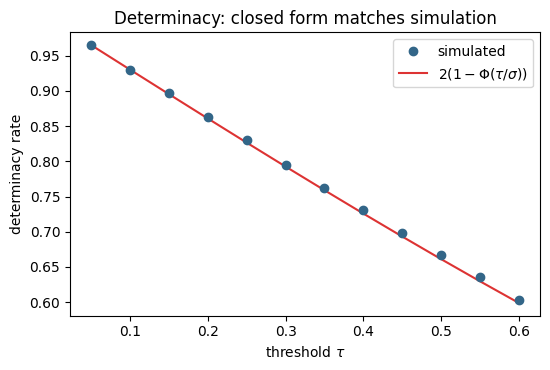

In [8]:
fig, ax = plt.subplots(figsize=(5.6, 3.8))
ax.plot(taus, sim, 'o', color='#368', label='simulated', zorder=3)
ax.plot(taus, ana, '-', color='#d33', label=r'$2(1-\Phi(\tau/\sigma))$')
ax.set_xlabel(r'threshold $\tau$'); ax.set_ylabel('determinacy rate'); ax.legend()
ax.set_title('Determinacy: closed form matches simulation')
fig.tight_layout(); fig.savefig(f'{FIGDIR}/nb7_T4_determinacy_closedform.png', dpi=150); plt.show()

## T5 - Equal weights are not the same as counting

**Statement.** With all weights equal, $w_i=c$, the SAW verdict (at $\tau=0$) is
$V_{\text{SAW}}=\operatorname{sign}(\sum_i a_i)$, the magnitude-weighted sum, while
counting votes gives $V_{\text{count}}=\operatorname{sign}(\sum_i \operatorname{sign}(a_i))$.
These disagree on a set of positive measure, so equal weights do not collapse the
model to counting. (The counterexample below is three principles; the disagreement
rate is measured on nine. With the model's default $\tau=0.2$ the equipoise band
adds further disagreement, so $\tau=0$ is the conservative comparison.)

**Proof.** A counterexample suffices: $a=(0.9,-0.4,-0.4)$ gives
$\sum a_i=0.1>0$ (SAW: for) but $\sum\operatorname{sign}(a_i)=-1<0$ (counting:
against). More generally the two disagree whenever a few large-magnitude
activations outweigh a larger number of small ones of the opposite sign. $\;\square$

This is the claim the earlier draft got wrong: with continuous activations, even
uniform weights keep the model in the business of weighing magnitudes, not
tallying votes.

In [9]:
a = np.array([0.9, -0.4, -0.4])
saw_one = int(np.sign(a.sum())); count_one = int(np.sign(np.sign(a).sum()))
# fraction of disagreement on random cases with equal weights
rng = np.random.default_rng(4); A = rng.uniform(-1, 1, (20000, 9))
saw_v = np.sign(A.sum(axis=1)); count_v = np.sign(np.sign(A).sum(axis=1))
disagree = float(np.mean(saw_v != count_v))
results['T5'] = dict(counterexample_saw=saw_one, counterexample_count=count_one, disagreement_rate=disagree)
print(f'counterexample (0.9,-0.4,-0.4): SAW={saw_one:+d} (for)  counting={count_one:+d} (against)')
print(f'equal-weight SAW disagrees with counting on {disagree:.1%} of random 9-principle cases')

counterexample (0.9,-0.4,-0.4): SAW=+1 (for)  counting=-1 (against)
equal-weight SAW disagrees with counting on 15.4% of random 9-principle cases


## Self-check
Each theorem's verification must hold; raises on drift.

In [10]:
ok = True
def check(n, c):
    global ok; ok = ok and bool(c); print(('PASS' if c else 'FAIL'), '-', n)
check('T1: SAW single-valued (no contradiction); validation foil contradicts', results['T1']['saw_single_valued'] and results['T1']['validation_contradiction_rate']>0.5)
check('T1: the 100% is construction, not frequency -- unstructured draws give less',
      results['T1']['antecedent_frequency']['independent'] < 0.9)
check('T2: conferred weight independent of invocation propensity', results['T2']['conferred_identical'] and results['T2']['uptake_differs'])
check('T3: thresholdless lexical exactly 0; library near 0; SAW well above both', results['T3']['lexical_thresholdless']==0.0 and results['T3']['lexical_library']<0.01 and results['T3']['saw_score']>5*results['T3']['lexical_library'])
check('T4: closed-form determinacy matches simulation (<0.02)', results['T4']['max_abs_error_closed_form']<0.02)
check('T4: sigma nearly constant WITHIN the dense families used', abs(results['T4']['sigma_uniform']-results['T4']['sigma_high'])<0.15)
check('T5: counterexample disagrees (SAW for, counting against)', results['T5']['counterexample_saw']==1 and results['T5']['counterexample_count']==-1)
check('T5: equal-weight SAW != counting on a positive fraction', results['T5']['disagreement_rate']>0.05)
print('\n'+('ALL CHECKS PASSED' if ok else 'SOME CHECKS FAILED')); assert ok, 'self-check failed'
import json; json.dump(results, open(f'{OUTDIR}/notebook7_results.json', 'w'), indent=2)

PASS - T1: SAW single-valued (no contradiction); validation foil contradicts
PASS - T1: the 100% is construction, not frequency -- unstructured draws give less
PASS - T2: conferred weight independent of invocation propensity
PASS - T3: thresholdless lexical exactly 0; library near 0; SAW well above both
PASS - T4: closed-form determinacy matches simulation (<0.02)
PASS - T4: sigma nearly constant WITHIN the dense families used
PASS - T5: counterexample disagrees (SAW for, counting against)
PASS - T5: equal-weight SAW != counting on a positive fraction

ALL CHECKS PASSED


## What this notebook establishes

Four of the strongest empirical findings are now theorems. A weighted sum cannot
contradict itself (T1); conferred weight is a different quantity from invocation
frequency, as a matter of what each is a function of (T2); a weighted sum weighs
magnitudes where a lexical rule cannot (T3); and the determinacy rate is a closed
form in the threshold with the weights entering only as a single scale, which is
why the threshold dominates (T4). T5 corrects a specific error in the earlier
draft. In each case the simulation is confirmation, not the load-bearing
evidence, which is what a theory paper should want.